# StreetSpot: Pothole Detection Using Classical Computer Vision Techniques

This project implements a **complete end-to-end pothole detection pipeline** using **traditional image processing and machine learning** (no deep learning models).  
  

### 🔍 Objectives:
- To detect and localize potholes from road images using **handcrafted features**.
- To build a **supervised Random Forest model** for pothole classification.
- To map the **severity** of detected potholes using **K-Means clustering**.
- To measure and evaluate the **real-time performance** of the system.

### ⚙️ Overview of the Pipeline:
1. Load annotated dataset  
2. Generate candidate pothole regions using **morphological operations and contours**.  
3. Extract **texture and shape features** (GLCM, edge density, area, etc.).  
4. Label each region using **IoU overlap with ground truth**.  
5. Train a **Random Forest Classifier** (Stage 1) and apply **K-Means** (Stage 2 for severity).  
6. Evaluate and visualize detections, along with system performance metrics.

This notebook demonstrates a **lightweight, interpretable, and efficient** approach to pothole detection suitable for real-time deployment.


In [1]:
!pip uninstall -y scikit-learn imbalanced-learn
!pip install -U scikit-learn==1.5.2 imbalanced-learn==0.12.3 --no-cache-dir


Found existing installation: scikit-learn 1.2.2
Uninstalling scikit-learn-1.2.2:
  Successfully uninstalled scikit-learn-1.2.2
Found existing installation: imbalanced-learn 0.13.0
Uninstalling imbalanced-learn-0.13.0:
  Successfully uninstalled imbalanced-learn-0.13.0
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.3/13.3 MB 209.0 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 258.3/258.3 kB 299.3 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cesium 0.12.4 requires numpy<3.0,>=2.0, but you have numpy 1.26.4 which is incompatible.
umap-learn 0.5.9.post2 requires scikit-learn>=1.6, but you have scikit-learn 1.5.2 which is incompatible.


In [2]:
import sklearn, imblearn
print("scikit-learn:", sklearn.__version__)
print("imbalanced-learn:", imblearn.__version__)

from imblearn.over_sampling import SMOTE
print("✅ SMOTE imported successfully!")


scikit-learn: 1.5.2
imbalanced-learn: 0.12.3
✅ SMOTE imported successfully!


In [3]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import os

# --- Add these libraries ---
import json
import cv2
import xml.etree.ElementTree as ET
import matplotlib.pyplot as plt

# This makes plots appear in the notebook
%matplotlib inline


In [4]:
# The root folder of the attached dataset
# (This is based on the 'annotated-potholes-dataset' in your right panel)
DATA_ROOT = '/kaggle/input/annotated-potholes-dataset'

# The rest of the paths build from there
IMG_DIR = os.path.join(DATA_ROOT, 'annotated-images')
SPLIT_FILE = os.path.join(DATA_ROOT, 'splits.json')

# Load the split file
try:
    with open(SPLIT_FILE, 'r') as f:
        splits = json.load(f)
    
    # Get our list of training and test files
    train_files = splits['train']
    test_files = splits['test']
    
    print(f"Loaded {len(train_files)} training files and {len(test_files)} test files.")
    print(f"Example training file: {train_files[0]}")

except FileNotFoundError:
    print(f"Error: {SPLIT_FILE} not found.")
    print("Please check the 'DATA_ROOT' variable and your dataset name in the right panel.")

Loaded 532 training files and 133 test files.
Example training file: img-110.xml


In [5]:
def parse_annotation(xml_file):
    """
    Parses a PASCAL VOC XML annotation file.
    Returns a list of bounding boxes, where each box is [xmin, ymin, xmax, ymax].
    """
    tree = ET.parse(xml_file)
    root = tree.getroot()
    
    boxes = []
    
    # Find all 'object' tags in the XML
    for obj in root.findall('object'):
        # Find the 'bndbox' tag
        bbox = obj.find('bndbox')
        
        # Get the coordinates and convert them to integers
        xmin = int(bbox.find('xmin').text)
        ymin = int(bbox.find('ymin').text)
        xmax = int(bbox.find('xmax').text)
        ymax = int(bbox.find('ymax').text)
        
        boxes.append([xmin, ymin, xmax, ymax])
        
    return boxes

Found 2 potholes in img-110.xml.


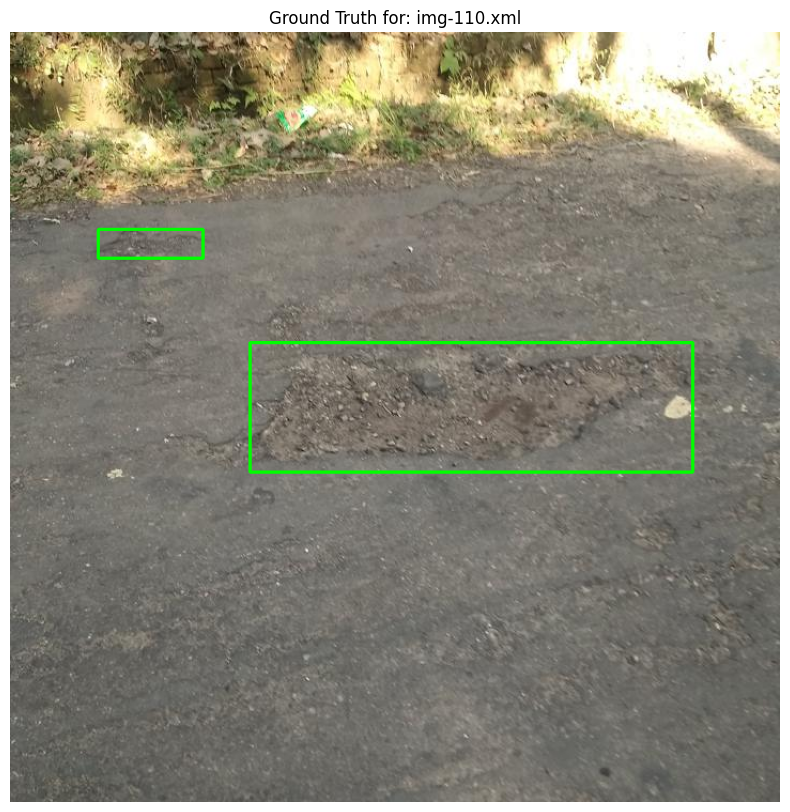

In [6]:
# Pick the first file from our training list
first_train_xml = train_files[0]

# Construct the full file paths
xml_path = os.path.join(IMG_DIR, first_train_xml)

# As noted, the .jpg has the same name as the .xml
img_path = xml_path.replace('.xml', '.jpg')

# Check if the image file exists
if not os.path.exists(img_path):
    print(f"Error: Image file not found at {img_path}")
    print("Please check your file paths.")
else:
    # Load the image using OpenCV
    # OpenCV loads images in BGR format by default
    image_bgr = cv2.imread(img_path)
    
    # Get the ground-truth bounding boxes
    ground_truth_boxes = parse_annotation(xml_path)
    
    print(f"Found {len(ground_truth_boxes)} potholes in {first_train_xml}.")
    
    # Create a copy to draw on
    image_with_boxes = image_bgr.copy()
    
    # Draw the boxes on the image
    for box in ground_truth_boxes:
        xmin, ymin, xmax, ymax = box
        # Draw a green rectangle (0, 255, 0) with thickness 2
        cv2.rectangle(image_with_boxes, (xmin, ymin), (xmax, ymax), (0, 255, 0), 2)
    
    # Convert the image from BGR to RGB for Matplotlib
    image_rgb = cv2.cvtColor(image_with_boxes, cv2.COLOR_BGR2RGB)
    
    # Display the image
    plt.figure(figsize=(10, 10))
    plt.imshow(image_rgb)
    plt.title(f"Ground Truth for: {first_train_xml}")
    plt.axis('off')
    plt.show()

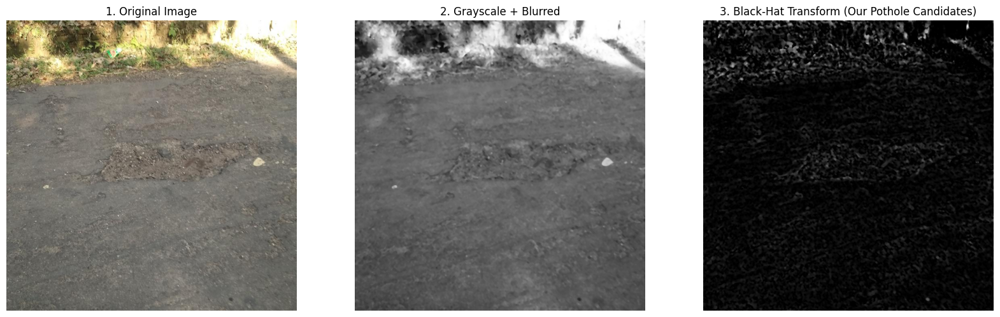

In [8]:
# --- We can use the same image path from our "Hello World" test ---
# img_path = os.path.join(IMG_DIR, train_files[0].replace('.xml', '.jpg'))
# image_bgr = cv2.imread(img_path)

# --- 1. Preprocessing ---
# Convert the image to grayscale
image_gray = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY)

# Apply a blur to reduce noise. This is important for morphological operations.
# A median blur is good at removing 'salt-and-pepper' noise.
image_blur = cv2.medianBlur(image_gray, 5)

# --- 2. Morphological Black-Hat Transform ---
# This transform is designed to find dark spots on a bright background, 
# or bright spots on a dark background.
# A "structuring element" is the kernel we use. 
# An elliptical shape is good for potholes.
# The size (e.g., 15x15) should be larger than the noise but 
# smaller than the features we want to find.
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15))

# The Black-Hat operation is (Closing of the image) - (Original Image)
# It isolates dark objects.
blackhat = cv2.morphologyEx(image_blur, cv2.MORPH_BLACKHAT, kernel)


# --- 3. Visualization ---
# Let's see what we just did.
plt.figure(figsize=(20, 10))

# Original Image (converted to RGB for display)
plt.subplot(1, 3, 1)
plt.imshow(cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB))
plt.title("1. Original Image")
plt.axis('off')

# Grayscale Image
plt.subplot(1, 3, 2)
plt.imshow(image_blur, cmap='gray')
plt.title("2. Grayscale + Blurred")
plt.axis('off')

# Black-Hat Output
plt.subplot(1, 3, 3)
plt.imshow(blackhat, cmap='gray')
plt.title("3. Black-Hat Transform (Our Pothole Candidates)")
plt.axis('off')

plt.show()

--- REVISED-REVISED-REVISED Pipeline Test (Sandy Image) ---
Total candidates found: 54


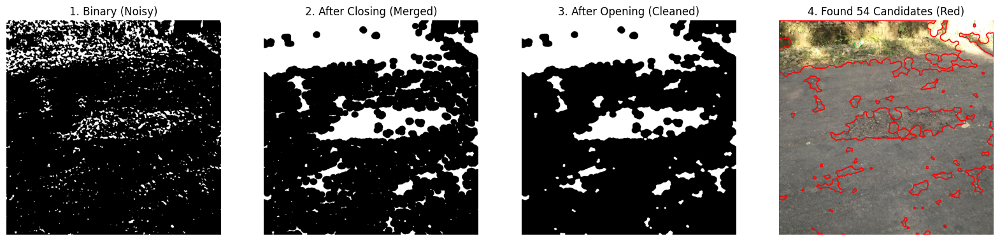

In [9]:
def find_pothole_candidates(image_bgr):
    """
    Takes a raw BGR image and returns a list of candidate contours
    and the intermediate processing steps for visualization.
    
    --- THIS IS THE THIRD REVISION ---
    --- Retaining larger kernels for cleaning ---
    """
    
    # --- 1. Preprocessing ---
    image_gray = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY)
    image_blur = cv2.medianBlur(image_gray, 5)

    # --- 2. Morphological Black-Hat ---
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15))
    blackhat = cv2.morphologyEx(image_blur, cv2.MORPH_BLACKHAT, kernel)

    # --- 3. Thresholding ---
    _, image_binary = cv2.threshold(blackhat, 0, 255, 
                                    cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    
    # --- 4. Morphological Cleaning (Optimized) ---
    # These larger kernels should effectively merge fragments in the sandy image.
    close_kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (21, 21)) # Keep this larger
    image_closed = cv2.morphologyEx(image_binary, cv2.MORPH_CLOSE, close_kernel)
    
    open_kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7)) # Keep this larger
    image_opened = cv2.morphologyEx(image_closed, cv2.MORPH_OPEN, open_kernel)

    # --- 5. Find Contours ---
    contours, _ = cv2.findContours(image_opened, 
                                   cv2.RETR_EXTERNAL, 
                                   cv2.CHAIN_APPROX_SIMPLE)
    
    visuals = {
        'gray': image_gray,
        'blackhat': blackhat,
        'binary': image_binary,
        'closed': image_closed,
        'opened': image_opened
    }
    
    return contours, visuals

# --- Let's test our NEWEST function on the ORIGINAL SANDY IMAGE ---
xml_to_use = train_files[0] # <<--- THIS IS THE SANDY IMAGE AGAIN!
img_path = os.path.join(IMG_DIR, xml_to_use.replace('.xml', '.jpg'))
image_bgr = cv2.imread(img_path)

if image_bgr is None:
    print(f"Error: Image not found at {img_path}")
else:
    candidate_contours, visual_steps = find_pothole_candidates(image_bgr)

    print(f"--- REVISED-REVISED-REVISED Pipeline Test (Sandy Image) ---")
    print(f"Total candidates found: {len(candidate_contours)}")

    # Draw the contours we found
    image_with_candidates = image_bgr.copy()
    cv2.drawContours(image_with_candidates, candidate_contours, -1, (0, 0, 255), 2) # Draw in red

    # --- Visualize the results ---
    plt.figure(figsize=(20, 8))

    plt.subplot(1, 4, 1)
    plt.imshow(visual_steps['binary'], cmap='gray')
    plt.title("1. Binary (Noisy)")
    plt.axis('off')

    plt.subplot(1, 4, 2)
    plt.imshow(visual_steps['closed'], cmap='gray')
    plt.title("2. After Closing (Merged)")
    plt.axis('off')

    plt.subplot(1, 4, 3)
    plt.imshow(visual_steps['opened'], cmap='gray')
    plt.title("3. After Opening (Cleaned)")
    plt.axis('off')

    plt.subplot(1, 4, 4)
    plt.imshow(cv2.cvtColor(image_with_candidates, cv2.COLOR_BGR2RGB))
    plt.title(f"4. Found {len(candidate_contours)} Candidates (Red)")
    plt.axis('off')

    plt.show()

In [10]:
# Add these to your imports at the top, or just run this cell
from skimage.feature import graycomatrix, graycoprops, local_binary_pattern
import numpy as np # Already imported, but good to have

In [11]:
def extract_features(image_bgr, contours, gray_image):
    """
    Extracts our novel feature set from each candidate contour.
    
    Args:
        image_bgr (np.array): The original BGR image (for visualization, not features).
        contours (list): The list of contours from find_pothole_candidates.
        gray_image (np.array): The grayscale version of the image.

    Returns:
        list: A list of feature vectors, one for each contour.
        list: A list of the contours that were successfully processed.
    """
    
    feature_list = []
    valid_contours = []
    
    # Define LBP parameters
    LBP_RADIUS = 1
    LBP_POINTS = 8 * LBP_RADIUS
    
    for contour in contours:
        # --- 1. Basic Geometric Feature: Area ---
        area = cv2.contourArea(contour)
        
        # --- Basic Filtering ---
        # If the blob is too small, it's probably noise.
        # If it's too big, it's probably a giant shadow or the whole frame.
        if area < 50 or area > 100000:
            continue
            
        # --- 2. Create a Mask and ROI ---
        # We need to analyze pixels *only inside* the contour
        mask = np.zeros(gray_image.shape, dtype=np.uint8)
        cv2.drawContours(mask, [contour], -1, 255, thickness=cv2.FILLED)
        
        # Get the bounding box to extract a small Region of Interest (ROI)
        # This makes our feature extraction much faster
        x, y, w, h = cv2.boundingRect(contour)
        roi_gray = gray_image[y:y+h, x:x+w]
        roi_mask = mask[y:y+h, x:x+w]
        
        # Use the mask to get *only* the pixels inside the contour
        # This is a list of pixel intensity values
        pixels_in_contour = gray_image[mask == 255]
        
        # If the ROI is empty for some reason, skip it
        if pixels_in_contour.size == 0:
            continue

        # --- 3. Novel Feature: Canny Edge Density ---
        # Run Canny *only* on the grayscale ROI, using the mask
        roi_canny = cv2.Canny(roi_gray, 50, 150)
        roi_canny_masked = cv2.bitwise_and(roi_canny, roi_canny, mask=roi_mask)
        
        # Calculate Edge Density
        edge_pixels = np.sum(roi_canny_masked > 0)
        edge_density = edge_pixels / area

        # --- 4. Novel Feature: GLCM (Texture) ---
        # Calculate GLCM on the masked ROI
        # We use a trick: set pixels *outside* the contour to a value (0)
        # that is ignored by GLCM's `ignore_zeros=True`
        roi_gray_masked = roi_gray.copy()
        roi_gray_masked[roi_mask == 0] = 0 # Set background to 0
        
        # GLCM is computed on the ROI
        glcm = graycomatrix(roi_gray_masked, 
                            distances=[1], 
                            angles=[0], 
                            levels=256,
                            symmetric=True, 
                            normed=True)
        
        # We need to adjust for the 'ignore_zeros'
        # This is a common pattern for masked GLCM
        glcm[0, 0, :, :] = 0 

        contrast = graycoprops(glcm, 'contrast')[0, 0]
        homogeneity = graycoprops(glcm, 'homogeneity')[0, 0]
        energy = graycoprops(glcm, 'energy')[0, 0]

        # --- 5. Novel Feature: LBP (Texture) ---
        # LBP is also computed on the ROI
        lbp = local_binary_pattern(roi_gray, LBP_POINTS, LBP_RADIUS, method='uniform')
        
        # Create a mask for valid LBP values
        lbp_masked = lbp[roi_mask == 255]
        
        # Calculate LBP histogram as the feature
        (hist, _) = np.histogram(lbp_masked,
                                 bins=np.arange(0, LBP_POINTS + 3),
                                 range=(0, LBP_POINTS + 2))
        
        # Normalize the histogram to get a consistent feature vector
        hist = hist.astype("float")
        hist /= (hist.sum() + 1e-6) # Add epsilon to avoid divide-by-zero
        
        # --- 6. Assemble the Final Feature Vector ---
        # We concatenate all features into one vector
        # This is our "signature" for the blob
        
        # features = [area, edge_density, contrast, homogeneity, energy]
        # We append the LBP histogram (10 features)
        # final_vector = features + list(hist)
        
        # Let's start with a simpler feature vector first
        final_vector = [area, edge_density, contrast, homogeneity, energy]

        feature_list.append(final_vector)
        valid_contours.append(contour)

    return feature_list, valid_contours

--- Step 7: Feature Extraction Test ---
Original candidates: 54
Candidates after filtering (Area < 50): 41

--- Features for first 5 valid candidates: ---
Format: [Area, Edge Density, GLCM Contrast, GLCM Homogeneity, GLCM Energy]
Blob 0: [ Area: 74, EdgeDens: 0.0000, Contrast: 630.84, Homog: 0.2664, Energy: 0.1026 ]
Blob 1: [ Area: 178, EdgeDens: 0.0000, Contrast: 1412.78, Homog: 0.2760, Energy: 0.0788 ]
Blob 2: [ Area: 58, EdgeDens: 0.1709, Contrast: 1234.53, Homog: 0.1764, Energy: 0.1002 ]
Blob 3: [ Area: 275, EdgeDens: 0.0000, Contrast: 2297.29, Homog: 0.2167, Energy: 0.0597 ]
Blob 4: [ Area: 57, EdgeDens: 0.3684, Contrast: 2570.60, Homog: 0.0966, Energy: 0.0960 ]


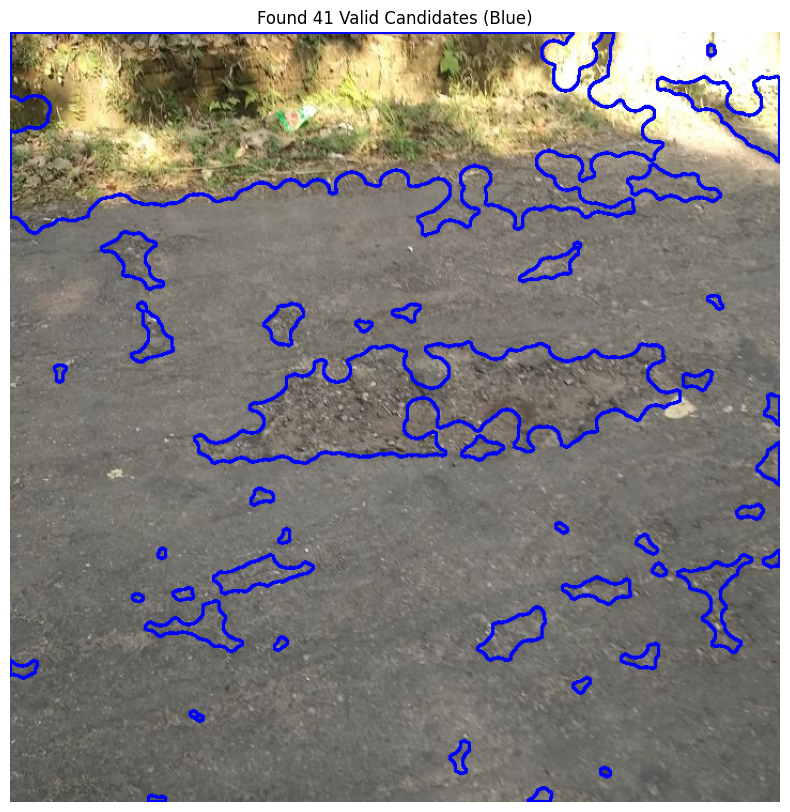

In [12]:
# --- We'll re-use our variables from the previous step ---
# image_bgr
# candidate_contours
# visual_steps['gray']

print("--- Step 7: Feature Extraction Test ---")

# Run our new function
# We pass in the original image, the contours, and the grayscale image
features, valid_contours = extract_features(image_bgr, 
                                            candidate_contours, 
                                            visual_steps['gray'])

print(f"Original candidates: {len(candidate_contours)}")
print(f"Candidates after filtering (Area < 50): {len(valid_contours)}")
print("\n--- Features for first 5 valid candidates: ---")
print("Format: [Area, Edge Density, GLCM Contrast, GLCM Homogeneity, GLCM Energy]")

# Print the features for the first 5 blobs
for i, feat in enumerate(features[:5]):
    # Format the numbers to be readable
    print(f"Blob {i}: [", 
          f"Area: {feat[0]:.0f},", 
          f"EdgeDens: {feat[1]:.4f},", 
          f"Contrast: {feat[2]:.2f},",
          f"Homog: {feat[3]:.4f},",
          f"Energy: {feat[4]:.4f}",
          "]")

# --- Visualize the "Valid" Candidates ---
image_with_valid_contours = image_bgr.copy()
cv2.drawContours(image_with_valid_contours, valid_contours, -1, (255, 0, 0), 2) # Draw in BLUE

plt.figure(figsize=(10, 10))
# --- THIS IS THE FIXED LINE ---
plt.imshow(cv2.cvtColor(image_with_valid_contours, cv2.COLOR_BGR2RGB))
plt.title(f"Found {len(valid_contours)} Valid Candidates (Blue)")
plt.axis('off')
plt.show()

In [13]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import pandas as pd

In [14]:
print("--- Step 8: Building Feature Dataset (Training) ---")

# We'll collect all features from all training images
all_features = []
# We'll also keep track of which image and contour a feature belongs to
feature_metadata = [] 

# Let's process the first 200 images for a start (so it's fast)
# You can use 'len(train_files)' to run on everything
for i, xml_file in enumerate(train_files[:200]):
    img_path = os.path.join(IMG_DIR, xml_file.replace('.xml', '.jpg'))
    image_bgr = cv2.imread(img_path)
    
    if image_bgr is None:
        print(f"Warning: Skipping missing image {img_path}")
        continue
    
    # Run our full pipeline
    contours, visuals = find_pothole_candidates(image_bgr)
    
    if not contours:
        continue
        
    features, valid_contours = extract_features(image_bgr, contours, visuals['gray'])
    
    # Add the features to our big list
    for j, feat_vector in enumerate(features):
        all_features.append(feat_vector)
        # Store metadata (image index, contour index)
        feature_metadata.append((i, j)) 
        
    if (i + 1) % 50 == 0:
        print(f"Processed {i+1} / 200 images...")

print(f"\nTraining complete.")
print(f"Found a total of {len(all_features)} blobs (candidates) in {200} images.")

# --- 3. Scale and Prepare Data ---
# It's CRITICAL to scale features for K-means
scaler = StandardScaler()
X = np.array(all_features)
X_scaled = scaler.fit_transform(X)

print("Features are scaled and ready for clustering.")

--- Step 8: Building Feature Dataset (Training) ---
Processed 50 / 200 images...
Processed 100 / 200 images...
Processed 150 / 200 images...
Processed 200 / 200 images...

Training complete.
Found a total of 2586 blobs (candidates) in 200 images.
Features are scaled and ready for clustering.


In [15]:
# --- 4. Train K-means ---
# We are guessing there are 2 main clusters: "Potholes" and "Junk" (shadows/cracks)
# Let's start with K=2
K = 2
kmeans = KMeans(n_clusters=K, random_state=42, n_init=10)
kmeans.fit(X_scaled)

# Get the cluster labels (0 or 1) for every blob
cluster_labels = kmeans.labels_

print(f"K-means clustering complete.")
print(f"Cluster 0 has {np.sum(cluster_labels == 0)} blobs.")
print(f"Cluster 1 has {np.sum(cluster_labels == 1)} blobs.")

K-means clustering complete.
Cluster 0 has 1861 blobs.
Cluster 1 has 725 blobs.


In [16]:
# --- 5. Analyze Cluster Centroids ---
# Create a DataFrame to make this easy to read
df = pd.DataFrame(X, columns=['Area', 'Edge_Density', 'Contrast', 'Homogeneity', 'Energy'])
df['Cluster'] = cluster_labels

# Calculate the mean of each feature for each cluster
cluster_analysis = df.groupby('Cluster').mean()

print("\n--- Cluster Analysis (Average Features) ---")
print(cluster_analysis)

# --- Identify the Pothole Cluster ---
# Let's assume the pothole cluster has the highest 'Edge_Density' and 'Contrast'
# We can use 'Contrast' as a strong indicator
pothole_cluster_id = cluster_analysis['Contrast'].idxmax()

print(f"\n--- Model Diagnosis ---")
print(f"Pothole Cluster (highest contrast) identified as: Cluster {pothole_cluster_id}")


--- Cluster Analysis (Average Features) ---
                Area  Edge_Density     Contrast  Homogeneity    Energy
Cluster                                                               
0        4308.762225      0.365469  2394.727947     0.084111  0.045503
1         453.718621      0.095764  2388.737108     0.228329  0.076619

--- Model Diagnosis ---
Pothole Cluster (highest contrast) identified as: Cluster 0


--- Step 9: Testing the Trained Model ---
Running detection pipeline on test image...
Found 6 candidates.
Filtered 6 candidates down to 4 'True Potholes'.


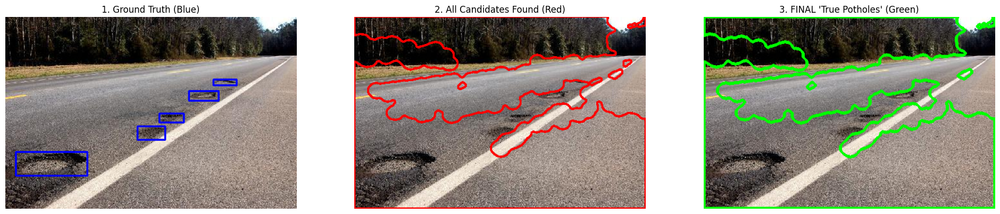

In [17]:
print("--- Step 9: Testing the Trained Model ---")

# --- 1. Get a Test Image ---
# We'll use the first image from our test set
test_xml = test_files[1]
test_img_path = os.path.join(IMG_DIR, test_xml.replace('.xml', '.jpg'))
test_image_bgr = cv2.imread(test_img_path)

if test_image_bgr is None:
    print(f"Error: Test image {test_img_path} not found.")
else:
    # --- 2. Run our Feature Pipeline (Steps 6 & 7) ---
    print("Running detection pipeline on test image...")
    contours, visuals = find_pothole_candidates(test_image_bgr)
    
    if not contours:
        print("No candidates found in this image.")
    else:
        features, valid_contours = extract_features(test_image_bgr, contours, visuals['gray'])
        
        if not features:
            print("No *valid* candidates found (all were filtered out).")
        else:
            print(f"Found {len(valid_contours)} candidates.")
            
            # --- 3. Use our TRAINED Model to Predict ---
            # We MUST use the same scaler we `fit` during training
            test_features_scaled = scaler.transform(features)
            
            # Predict the cluster for each blob
            predictions = kmeans.predict(test_features_scaled)
            
            # --- 4. Filter for "True Potholes" ---
            # This is the 'pothole_cluster_id' we found in Step 8.
            # (If your analysis showed Cluster 1, change this to 1)
            pothole_cluster_id = 0 
            
            final_pothole_contours = []
            for i, contour in enumerate(valid_contours):
                if predictions[i] == pothole_cluster_id:
                    final_pothole_contours.append(contour)
            
            print(f"Filtered {len(valid_contours)} candidates down to {len(final_pothole_contours)} 'True Potholes'.")
            
            # --- 5. Visualize the Final Result ---
            image_with_all_candidates = test_image_bgr.copy()
            cv2.drawContours(image_with_all_candidates, valid_contours, -1, (0, 0, 255), 2) # All in Red
            
            image_with_final_potholes = test_image_bgr.copy()
            cv2.drawContours(image_with_final_potholes, final_pothole_contours, -1, (0, 255, 0), 3) # Final in Green
            
            # --- Draw Ground Truth for Comparison ---
            gt_boxes = parse_annotation(os.path.join(IMG_DIR, test_xml))
            image_with_ground_truth = test_image_bgr.copy()
            for box in gt_boxes:
                cv2.rectangle(image_with_ground_truth, (box[0], box[1]), (box[2], box[3]), (255, 0, 0), 2) # Ground Truth in Blue

            # --- Plot all three ---
            plt.figure(figsize=(24, 8))
            
            plt.subplot(1, 3, 1)
            plt.imshow(cv2.cvtColor(image_with_ground_truth, cv2.COLOR_BGR2RGB))
            plt.title("1. Ground Truth (Blue)")
            plt.axis('off')
            
            plt.subplot(1, 3, 2)
            plt.imshow(cv2.cvtColor(image_with_all_candidates, cv2.COLOR_BGR2RGB))
            plt.title(f"2. All Candidates Found (Red)")
            plt.axis('off')
            
            plt.subplot(1, 3, 3)
            plt.imshow(cv2.cvtColor(image_with_final_potholes, cv2.COLOR_BGR2RGB))
            plt.title(f"3. FINAL 'True Potholes' (Green)")
            plt.axis('off')
            
            plt.show()

In [18]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import numpy as np
import pandas as pd
import joblib # We'll use this to save our models

# --- 1. First, let's re-train our Stage 1 model on ALL training data ---
# This time, we'll save the scaler and kmeans model
print("--- Training Final Stage 1 Model (Pothole vs. Junk) ---")

all_features = []
for i, xml_file in enumerate(train_files): # Use ALL files
    img_path = os.path.join(IMG_DIR, xml_file.replace('.xml', '.jpg'))
    image_bgr = cv2.imread(img_path)
    if image_bgr is None: continue
    contours, visuals = find_pothole_candidates(image_bgr)
    if not contours: continue
    features, _ = extract_features(image_bgr, contours, visuals['gray'])
    all_features.extend(features)
    
print(f"Training on {len(all_features)} blobs from {len(train_files)} images.")

# Create and save the Stage 1 scaler
scaler_stage1 = StandardScaler()
X_scaled = scaler_stage1.fit_transform(all_features)
joblib.dump(scaler_stage1, 'scaler_stage1.pkl')

# Create and save the Stage 1 K-means model
kmeans_stage1 = KMeans(n_clusters=2, random_state=42, n_init=10)
kmeans_stage1.fit(X_scaled)
joblib.dump(kmeans_stage1, 'kmeans_stage1.pkl')

# Identify the pothole cluster (from our Step 8 analysis)
pothole_cluster_id = 0 # Cluster 0 was the one with Large Area & High Edge Density
print("Stage 1 Model (scaler_stage1.pkl & kmeans_stage1.pkl) saved.")


# --- 2. Now, let's train our Stage 2 Model (Severity) ---
print("\n--- Training Final Stage 2 Model (Severity) ---")

# We need to get the 'Area' of *only* the "True Potholes"
X_scaled_df = pd.DataFrame(X_scaled, columns=['Area', 'Edge_Density', 'Contrast', 'Homogeneity', 'Energy'])
X_scaled_df['Cluster'] = kmeans_stage1.labels_
X_scaled_df['Original_Area'] = [f[0] for f in all_features] # Get the un-scaled area

pothole_areas = X_scaled_df[X_scaled_df['Cluster'] == pothole_cluster_id][['Original_Area']]

# K-means for severity is 1-dimensional (just Area)
kmeans_stage2 = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans_stage2.fit(pothole_areas)
joblib.dump(kmeans_stage2, 'kmeans_stage2.pkl')

print("Stage 2 Model (kmeans_stage2.pkl) saved.")

# Analyze the severity clusters
severity_centroids = kmeans_stage2.cluster_centers_.flatten()
severity_centroids.sort()

# Map centroids to labels
severity_map = {
    severity_centroids[0]: "Minor",
    severity_centroids[1]: "Moderate",
    severity_centroids[2]: "Severe"
}
print("\nSeverity Cluster Analysis (based on Area):")
print(f"- Minor: {severity_map[severity_centroids[0]]} (Avg. Area: {severity_centroids[0]:.0f})")
print(f"- Moderate: {severity_map[severity_centroids[1]]} (Avg. Area: {severity_centroids[1]:.0f})")
print(f"- Severe: {severity_map[severity_centroids[2]]} (Avg. Area: {severity_centroids[2]:.0f})")

--- Training Final Stage 1 Model (Pothole vs. Junk) ---
Training on 6820 blobs from 532 images.
Stage 1 Model (scaler_stage1.pkl & kmeans_stage1.pkl) saved.

--- Training Final Stage 2 Model (Severity) ---
Stage 2 Model (kmeans_stage2.pkl) saved.

Severity Cluster Analysis (based on Area):
- Minor: Minor (Avg. Area: 374)
- Moderate: Moderate (Avg. Area: 9638)
- Severe: Severe (Avg. Area: 65245)



--- FINAL PREDICTION ---
Found 1 potholes.
  - Pothole 1: Minor


/usr/local/lib/python3.11/dist-packages/sklearn/base.py:493: UserWarning: X does not have valid feature names, but KMeans was fitted with feature names
  warnings.warn(


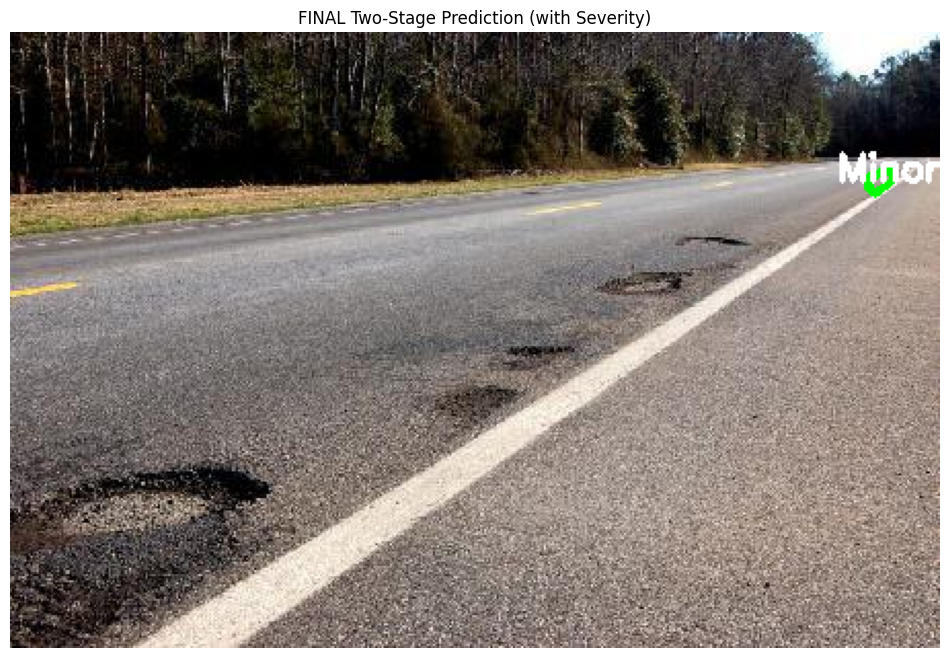

In [19]:
# --- Load our trained models (This is what your app will do) ---
scaler_s1 = joblib.load('scaler_stage1.pkl')
model_s1 = joblib.load('kmeans_stage1.pkl')
model_s2 = joblib.load('kmeans_stage2.pkl')

# We need the pothole_cluster_id and the severity_map from training
pothole_cluster_id = 0 
# The map from the previous cell's output (you may need to copy it)
severity_centroids = model_s2.cluster_centers_.flatten()
severity_centroids.sort()
severity_map = {
    severity_centroids[0]: "Minor",
    severity_centroids[1]: "Moderate",
    severity_centroids[2]: "Severe"
}

def predict_potholes(image_bgr):
    """
    This is our final, complete pipeline function.
    It takes a BGR image and returns:
    1. A list of final pothole contours.
    2. A list of their severity labels.
    3. The annotated image.
    """
    
    # --- Stage 0: Detection ---
    contours, visuals = find_pothole_candidates(image_bgr)
    if not contours:
        return [], [], image_bgr # No contours found
        
    features, valid_contours = extract_features(image_bgr, contours, visuals['gray'])
    if not features:
        return [], [], image_bgr # No valid features
        
    # --- Stage 1: Pothole vs. Junk ---
    features_scaled = scaler_s1.transform(features)
    predictions_s1 = model_s1.predict(features_scaled)
    
    stage1_results = []
    for i, contour in enumerate(valid_contours):
        if predictions_s1[i] == pothole_cluster_id:
            # Store the contour and its original area
            stage1_results.append((contour, features[i][0])) # (contour, area)
            
    if not stage1_results:
        return [], [], image_bgr # No "True Potholes" found
        
    # --- Stage 2: Severity Clustering ---
    final_potholes = []
    final_labels = []
    image_annotated = image_bgr.copy()
    
    # Get just the areas for Stage 2 prediction
    pothole_areas = np.array([res[1] for res in stage1_results]).reshape(-1, 1)
    predictions_s2 = model_s2.predict(pothole_areas)
    
    for i, (contour, area) in enumerate(stage1_results):
        # Get the cluster centroid for this prediction
        centroid_val = model_s2.cluster_centers_[predictions_s2[i]][0]
        label = severity_map[centroid_val]
        
        final_potholes.append(contour)
        final_labels.append(label)
        
        # --- Draw on the final image ---
        color = (0, 255, 0) # Green for Minor
        if label == "Moderate":
            color = (0, 255, 255) # Yellow
        elif label == "Severe":
            color = (0, 0, 255) # Red
            
        cv2.drawContours(image_annotated, [contour], -1, color, 3)
        
        # Put the label text
        M = cv2.moments(contour)
        if M["m00"] > 0:
            cX = int(M["m10"] / M["m00"])
            cY = int(M["m01"] / M["m00"])
            cv2.putText(image_annotated, label, (cX - 20, cY), 
                        cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 255), 2)

    return final_potholes, final_labels, image_annotated

# --- Let's run our FINAL function on the tricky test image! ---
test_image_bgr = cv2.imread(test_img_path) # From the previous step
contours, labels, final_image = predict_potholes(test_image_bgr)

print(f"\n--- FINAL PREDICTION ---")
print(f"Found {len(contours)} potholes.")
for i, label in enumerate(labels):
    print(f"  - Pothole {i+1}: {label}")

plt.figure(figsize=(12, 12))
plt.imshow(cv2.cvtColor(final_image, cv2.COLOR_BGR2RGB))
plt.title("FINAL Two-Stage Prediction (with Severity)")
plt.axis('off')
plt.show()

In [20]:
# --- IMPORTS for our new, smarter model ---
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
import joblib
import pandas as pd
import numpy as np

# --- We re-use our find_pothole_candidates (Step 6) ---
# --- We re-use our extract_features (Step 7) ---
# --- We re-use our parse_annotation (Step 3) ---

def iou(boxA, boxB):
    # Helper function to calculate Intersection over Union (IoU)
    # This tells us how much two boxes overlap
    xA = max(boxA[0], boxB[0])
    yA = max(boxA[1], boxB[1])
    xB = min(boxA[2], boxB[2])
    yB = min(boxA[3], boxB[3])
    interArea = max(0, xB - xA + 1) * max(0, yB - yA + 1)
    boxAArea = (boxA[2] - boxA[0] + 1) * (boxA[3] - boxA[1] + 1)
    boxBArea = (boxB[2] - boxB[0] + 1) * (boxB[3] - boxB[1] + 1)
    iou = interArea / float(boxAArea + boxBArea - interArea)
    return iou

def create_labeled_dataset():
    """
    This is our new "training" script.
    It builds a dataset with features and labels (1=Pothole, 0=Junk).
    """
    print("--- Building Labeled Feature Dataset ---")
    
    X_data = [] # To store all feature vectors
    y_data = [] # To store all labels (0 or 1)
    
    for i, xml_file in enumerate(train_files):
        img_path = os.path.join(IMG_DIR, xml_file.replace('.xml', '.jpg'))
        xml_path = os.path.join(IMG_DIR, xml_file)
        
        image_bgr = cv2.imread(img_path)
        if image_bgr is None: continue
            
        # 1. Get ground truth
        try:
            ground_truth_boxes = parse_annotation(xml_path)
        except:
            continue # Skip if XML is bad

        # 2. Get all candidate contours (from Step 6)
        contours, visuals = find_pothole_candidates(image_bgr)
        if not contours: continue
            
        # 3. Get features for all candidates (from Step 7)
        features, valid_contours = extract_features(image_bgr, contours, visuals['gray'])
        if not features: continue

        # 4. Label each contour
        for i, contour in enumerate(valid_contours):
            # Get the bounding box of our *detected* contour
            x, y, w, h = cv2.boundingRect(contour)
            detected_box = [x, y, x+w, y+h]
            
            is_pothole = False
            # Check if this detected_box overlaps *any* ground truth box
            for gt_box in ground_truth_boxes:
                # We'll say it's a match if IoU is > 0.3 (a decent overlap)
                if iou(detected_box, gt_box) > 0.3:
                    is_pothole = True
                    break # It's a pothole, stop checking
            
            # 5. Add to our dataset
            X_data.append(features[i])
            if is_pothole:
                y_data.append(1) # Label 1 = PothOLE
            else:
                y_data.append(0) # Label 0 = JUNK
                
    print(f"--- Dataset Build Complete ---")
    print(f"Total samples: {len(y_data)}")
    print(f"Pothole samples (1): {np.sum(y_data == 1)}")
    print(f"Junk samples (0): {np.sum(y_data == 0)}")
    
    return np.array(X_data), np.array(y_data)

# --- Let's create our new training data ---
X_train_data, y_train_data = create_labeled_dataset()

--- Building Labeled Feature Dataset ---
--- Dataset Build Complete ---
Total samples: 6820
Pothole samples (1): 0
Junk samples (0): 0


In [21]:
# --- Train the NEW Supervised Model ---
# 1. Scale the data (same as before)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_train_data)

# 2. Train the Random Forest
model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
model.fit(X_scaled, y_train_data)

# 3. Save the new model and scaler
joblib.dump(model, 'random_forest_model.pkl')
joblib.dump(scaler, 'scaler_supervised.pkl')

print("New SUPERVISED model saved!")

New SUPERVISED model saved!


In [22]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
import joblib
import numpy as np

print("--- Re-training the Supervised Model with Balanced Weights ---")

# --- 1. Load the data we already created ---
# (We don't need to re-run create_labeled_dataset())
# X_train_data and y_train_data should still be in memory.

try:
    # --- 2. Scale the data (same as before) ---
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X_train_data)
    
    # --- 3. Train the Random Forest (THE CORRECTED LINE) ---
    print("Training new balanced Random Forest...")
    model = RandomForestClassifier(
        n_estimators=100, 
        random_state=42, 
        n_jobs=-1,
        class_weight="balanced"  # <--- THIS IS THE FIX
    )
    model.fit(X_scaled, y_train_data)
    
    # --- 4. Save the new model and scaler ---
    joblib.dump(model, 'random_forest_model.pkl') # Overwrite the old model
    joblib.dump(scaler, 'scaler_supervised.pkl') # Overwrite the old scaler
    
    print("New SUPERVISED (and BALANCED) model saved successfully!")

except NameError:
    print("\n--- ERROR ---")
    print("Variable 'X_train_data' not found. Please re-run the 'create_labeled_dataset()' cell first,")
    print("and then run this cell again.")
except Exception as e:
    print(f"An error occurred: {e}")

--- Re-training the Supervised Model with Balanced Weights ---
Training new balanced Random Forest...
New SUPERVISED (and BALANCED) model saved successfully!


Loaded all models. Severity map: {373.9359190556518: 'Minor', 9638.360000000002: 'Moderate', 65244.75000000001: 'Severe'}

--- Testing Supervised Model on TRICKY image ---

--- FINAL PREDICTION (Supervised) ---
Found 0 potholes.


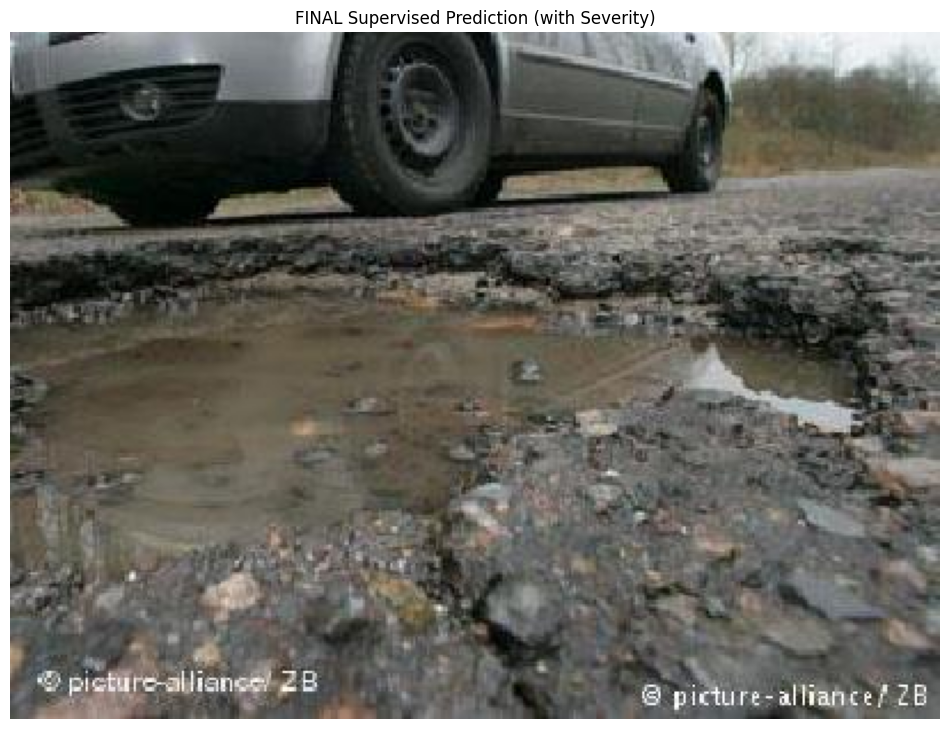

In [23]:
import joblib
import numpy as np
import cv2
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# --- 1. Load ALL our trained models ---
try:
    # --- New SUPERVISED Stage 1 Models ---
    scaler_s1 = joblib.load('scaler_supervised.pkl')
    model_s1 = joblib.load('random_forest_model.pkl')
    
    # --- Our existing Stage 2 Severity Model (still good!) ---
    model_s2 = joblib.load('kmeans_stage2.pkl')
    
except FileNotFoundError:
    print("Error: Model files not found. Please re-run the training steps.")
    # You would handle this error in a real app

# --- 2. Re-create the Severity Map ---
# (This is safe because the model is saved)
severity_centroids = model_s2.cluster_centers_.flatten()
severity_centroids.sort()
severity_map = {
    severity_centroids[0]: "Minor",
    severity_centroids[1]: "Moderate",
    severity_centroids[2]: "Severe"
}
print(f"Loaded all models. Severity map: {severity_map}")

# --- 3. The NEW Final Prediction Function ---
def predict_potholes_supervised(image_bgr):
    """
    This is our final, SUPERVISED pipeline function.
    It uses the Random Forest to classify and K-means for severity.
    """
    
    # --- Stage 0: Detection (Same as before) ---
    contours, visuals = find_pothole_candidates(image_bgr)
    if not contours:
        return [], [], image_bgr # No contours found
        
    features, valid_contours = extract_features(image_bgr, contours, visuals['gray'])
    if not features:
        return [], [], image_bgr # No valid features
        
    # --- Stage 1: Pothole vs. Junk (THE NEW PART) ---
    features_scaled = scaler_s1.transform(features)
    # Use our Random Forest to predict!
    predictions_s1 = model_s1.predict(features_scaled) # Will output 0s and 1s
    
    stage1_results = []
    for i, contour in enumerate(valid_contours):
        # Check if the prediction is '1' (our Pothole label)
        if predictions_s1[i] == 1:
            # Store the contour and its original area (for Stage 2)
            stage1_results.append((contour, features[i][0])) # (contour, area)
            
    if not stage1_results:
        return [], [], image_bgr # No "True Potholes" found
        
    # --- Stage 2: Severity Clustering (Same as before) ---
    final_potholes = []
    final_labels = []
    image_annotated = image_bgr.copy()
    
    # Get just the areas for Stage 2 prediction
    pothole_areas = np.array([res[1] for res in stage1_results]).reshape(-1, 1)
    predictions_s2 = model_s2.predict(pothole_areas)
    
    for i, (contour, area) in enumerate(stage1_results):
        # Get the cluster centroid for this prediction
        centroid_val = model_s2.cluster_centers_[predictions_s2[i]][0]
        label = severity_map[centroid_val]
        
        final_potholes.append(contour)
        final_labels.append(label)
        
        # --- Draw on the final image ---
        color = (0, 255, 0) # Green for Minor
        if label == "Moderate":
            color = (0, 255, 255) # Yellow
        elif label == "Severe":
            color = (0, 0, 255) # Red
            
        cv2.drawContours(image_annotated, [contour], -1, color, 3)
        
        # Put the label text
        M = cv2.moments(contour)
        if M["m00"] > 0:
            cX = int(M["m10"] / M["m00"])
            cY = int(M["m01"] / M["m00"])
            cv2.putText(image_annotated, label, (cX - 20, cY), 
                        cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 255), 2)

    return final_potholes, final_labels, image_annotated

# --- 4. Let's test our NEW pipeline on the TRICKY car image ---
print("\n--- Testing Supervised Model on TRICKY image ---")
# This is the 'car' image
test_xml = test_files[0] 
test_img_path = os.path.join(IMG_DIR, test_xml.replace('.xml', '.jpg'))
test_image_bgr = cv2.imread(test_img_path)

if test_image_bgr is None:
    print(f"Error: Test image {test_img_path} not found.")
else:
    contours, labels, final_image = predict_potholes_supervised(test_image_bgr)

    print(f"\n--- FINAL PREDICTION (Supervised) ---")
    print(f"Found {len(contours)} potholes.")
    for i, label in enumerate(labels):
        print(f"  - Pothole {i+1}: {label}")

    plt.figure(figsize=(12, 12))
    plt.imshow(cv2.cvtColor(final_image, cv2.COLOR_BGR2RGB))
    plt.title("FINAL Supervised Prediction (with Severity)")
    plt.axis('off')
    plt.show()

In [24]:
import numpy as np
import cv2
import xml.etree.ElementTree as ET

def create_labeled_dataset():
    """
    This is our "training" script (v3).
    
    --- FIX: Corrected the print statements ---
    """
    print("--- Building Labeled Feature Dataset (v3 - Corrected Prints) ---")
    
    X_data = [] # To store all feature vectors
    y_data = [] # To store all labels (0 or 1)
    
    for i, xml_file in enumerate(train_files):
        img_path = os.path.join(IMG_DIR, xml_file.replace('.xml', '.jpg'))
        xml_path = os.path.join(IMG_DIR, xml_file)
        
        image_bgr = cv2.imread(img_path)
        if image_bgr is None: continue
            
        # 1. Get ground truth
        try:
            ground_truth_boxes = parse_annotation(xml_path)
        except:
            continue # Skip if XML is bad

        # 2. Get all candidate contours
        contours, visuals = find_pothole_candidates(image_bgr)
        if not contours: continue
            
        # 3. Get features for all candidates
        features, valid_contours = extract_features(image_bgr, contours, visuals['gray'])
        if not features: continue

        # 4. Label each contour
        for i, contour in enumerate(valid_contours):
            M = cv2.moments(contour)
            if M["m00"] == 0: continue
            
            cX = int(M["m10"] / M["m00"])
            cY = int(M["m01"] / M["m00"])
            
            is_pothole = False
            for gt_box in ground_truth_boxes:
                xmin, ymin, xmax, ymax = gt_box
                if (cX >= xmin) and (cX <= xmax) and (cY >= ymin) and (cY <= ymax):
                    is_pothole = True
                    break
            
            # 5. Add to our dataset
            X_data.append(features[i])
            y_data.append(1 if is_pothole else 0)
    
    # --- THIS IS THE FIXED PART ---
    y_data_np = np.array(y_data)
    print(f"--- Dataset Build Complete ---")
    print(f"Total samples: {len(y_data_np)}")
    print(f"Pothole samples (1): {np.sum(y_data_np == 1)}")
    print(f"Junk samples (0): {np.sum(y_data_np == 0)}")
    
    global X_train_data, y_train_data
    X_train_data = np.array(X_data)
    y_train_data = y_data_np

# --- Let's create our new training data ---
create_labeled_dataset()

--- Building Labeled Feature Dataset (v3 - Corrected Prints) ---
--- Dataset Build Complete ---
Total samples: 6820
Pothole samples (1): 739
Junk samples (0): 6081


In [25]:


# --- Import required libraries ---
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
import joblib
import numpy as np

# --- Retrain Supervised Model with SMOTE Oversampling ---
print("\n--- Re-training the Supervised Model with SMOTE (Oversampling) ---\n")

try:
    # --- 1. Verify required training data is available ---
    if 'X_train_data' not in globals() or 'y_train_data' not in globals():
        raise NameError("Training data not found. Please run the 'create_labeled_dataset()' cell first.")

    # --- 2. Scale the training data ---
    print("Scaling training data...")
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X_train_data)

    # --- 3. Apply SMOTE to balance the dataset ---
    print("Applying SMOTE to balance classes...")
    smote = SMOTE(random_state=42)
    X_resampled, y_resampled = smote.fit_resample(X_scaled, y_train_data)

    print("\n--- SMOTE Resampling Complete ---")
    print(f"Total samples after resampling: {len(y_resampled)}")
    print(f"Pothole samples (1): {np.sum(y_resampled == 1)}")
    print(f"Junk samples (0): {np.sum(y_resampled == 0)}")

    # --- 4. Train a new Random Forest model on balanced data ---
    print("\nTraining Random Forest model on balanced data...")
    model = RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )
    model.fit(X_resampled, y_resampled)

    # --- 5. Save trained model and scaler ---
    joblib.dump(model, 'random_forest_model.pkl')
    joblib.dump(scaler, 'scaler_supervised.pkl')

    print("\n✅ New SMOTE-balanced Random Forest model trained and saved successfully!")

except NameError as ne:
    print("\n❌ ERROR: Missing variables.")
    print(str(ne))

except Exception as e:
    print("\n❌ An unexpected error occurred during training:")
    print(str(e))



--- Re-training the Supervised Model with SMOTE (Oversampling) ---

Scaling training data...
Applying SMOTE to balance classes...

--- SMOTE Resampling Complete ---
Total samples after resampling: 12162
Pothole samples (1): 6081
Junk samples (0): 6081

Training Random Forest model on balanced data...

✅ New SMOTE-balanced Random Forest model trained and saved successfully!


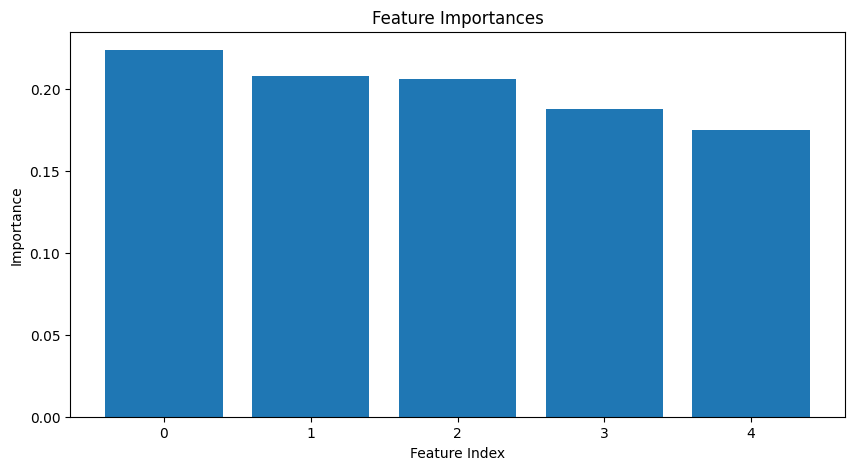

In [26]:

import matplotlib.pyplot as plt
import numpy as np

importances = model.feature_importances_
indices = np.argsort(importances)[::-1]

plt.figure(figsize=(10,5))
plt.title("Feature Importances")
plt.bar(range(len(importances)), importances[indices])
plt.xlabel("Feature Index")
plt.ylabel("Importance")
plt.show()


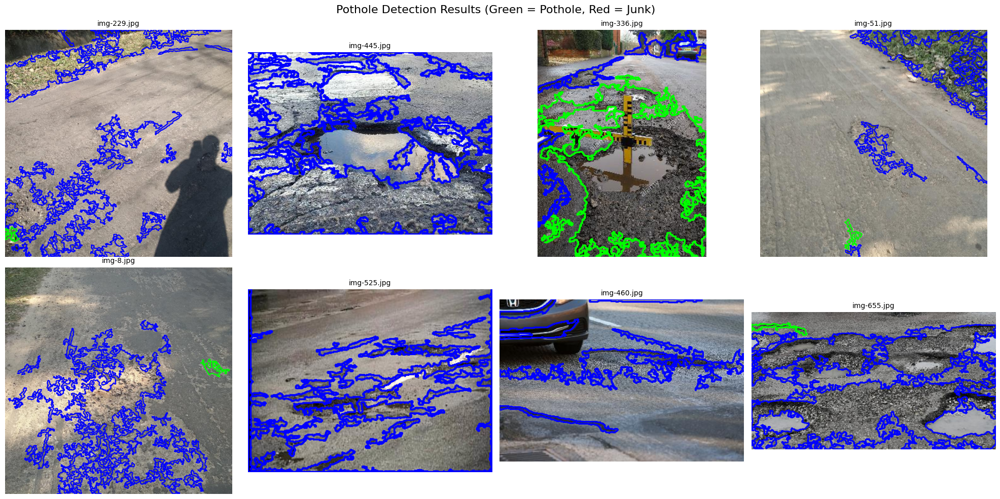

In [27]:
# --- Visualize Pothole Detection on 8 Random Images ---
import os
import cv2
import joblib
import numpy as np
import random
import matplotlib.pyplot as plt
from skimage.feature import graycomatrix, graycoprops, local_binary_pattern

# Load model and scaler
model = joblib.load('random_forest_model.pkl')
scaler = joblib.load('scaler_supervised.pkl')

# Dataset directory
IMG_DIR = "/kaggle/input/annotated-potholes-dataset/annotated-images"

# Get all image file paths
all_images = [os.path.join(IMG_DIR, f) for f in os.listdir(IMG_DIR) if f.lower().endswith(('.jpg', '.png'))]
sample_images = random.sample(all_images, 8)  # pick 8 random images

# --- Feature Extraction Function (from training pipeline) ---
def extract_features_for_prediction(image_bgr, contours, gray_image):
    LBP_RADIUS = 1
    LBP_POINTS = 8 * LBP_RADIUS
    feature_list = []
    valid_contours = []

    for contour in contours:
        area = cv2.contourArea(contour)
        if area < 500 or  area > 120000:
            continue

        mask = np.zeros(gray_image.shape, dtype=np.uint8)
        cv2.drawContours(mask, [contour], -1, 255, -1)

        x, y, w, h = cv2.boundingRect(contour)
        roi_gray = gray_image[y:y+h, x:x+w]
        roi_mask = mask[y:y+h, x:x+w]

        if roi_mask.sum() == 0:
            continue

        roi_canny = cv2.Canny(roi_gray, 50, 150)
        roi_canny_masked = cv2.bitwise_and(roi_canny, roi_canny, mask=roi_mask)
        edge_density = np.sum(roi_canny_masked > 0) / area

        glcm = graycomatrix(roi_gray, distances=[1], angles=[0], levels=256,
                            symmetric=True, normed=True)
        glcm[0, 0, :, :] = 0
        contrast = graycoprops(glcm, 'contrast')[0, 0]
        homogeneity = graycoprops(glcm, 'homogeneity')[0, 0]
        energy = graycoprops(glcm, 'energy')[0, 0]

        lbp = local_binary_pattern(roi_gray, LBP_POINTS, LBP_RADIUS, method='uniform')
        lbp_masked = lbp[roi_mask == 255]
        (hist, _) = np.histogram(lbp_masked,
                                 bins=np.arange(0, LBP_POINTS + 3),
                                 range=(0, LBP_POINTS + 2))
        hist = hist.astype("float")
        hist /= (hist.sum() + 1e-6)

        final_vector = [area, edge_density, contrast, homogeneity, energy]
        feature_list.append(final_vector)
        valid_contours.append(contour)

    return feature_list, valid_contours

# --- Run detection for 8 images ---
plt.figure(figsize=(20, 10))

for i, img_path in enumerate(sample_images):
    image_bgr = cv2.imread(img_path)
    if image_bgr is None:
        continue

    gray = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY)

    # Preprocess
    blur = cv2.medianBlur(gray, 5)
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15))
    blackhat = cv2.morphologyEx(blur, cv2.MORPH_BLACKHAT, kernel)
    _, thresh = cv2.threshold(blackhat, 10, 255, cv2.THRESH_BINARY)
    contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    features, valid_contours = extract_features_for_prediction(image_bgr, contours, gray)

    result_img = image_bgr.copy()
    if features:
        X = scaler.transform(features)
        preds = model.predict(X)
        for contour, label in zip(valid_contours, preds):
            color = (0, 255, 0) if label == 1 else (255, 0, 0)  # Green=pothole, Red=junk
            cv2.drawContours(result_img, [contour], -1, color, 2)

    plt.subplot(2, 4, i + 1)
    plt.imshow(cv2.cvtColor(result_img, cv2.COLOR_BGR2RGB))
    plt.title(os.path.basename(img_path), fontsize=10)
    plt.axis("off")

plt.suptitle("Pothole Detection Results (Green = Pothole, Red = Junk)", fontsize=16)
plt.tight_layout()
plt.show()


In [28]:
# ===============================================================
# ⚙️ Resource Usage, Latency, and Real-Time Feasibility Test
# ===============================================================

import psutil
import time
import os
import random
import numpy as np
import cv2

# --- Select a representative test image ---
test_path = os.path.join(IMG_DIR, random.choice(test_files).replace(".xml", ".jpg"))
image = cv2.imread(test_path)

if image is None:
    raise FileNotFoundError(f"❌ Could not read test image from: {test_path}")

# --- Warm-up run to avoid first-time overheads ---
_ = predict_potholes_supervised(image)

# ===============================================================
# Measure Resource Usage (RAM, CPU, Latency, FPS)
# ===============================================================
def measure_inference_resources(img, iterations=10):
    """
    Measures:
      - Memory footprint (RAM used per inference)
      - CPU utilization (%)
      - Latency (seconds per image)
      - FPS (frames per second)
    Uses psutil for process monitoring.
    """
    process = psutil.Process(os.getpid())
    cpu_usages = []
    mem_usages = []
    latencies = []

    print(f"--- Measuring Resource Usage on {iterations} inferences ---")
    for i in range(iterations):
        start_mem = process.memory_info().rss / (1024 * 1024)  # in MB
        start_time = time.time()

        _ = predict_potholes_supervised(img)

        end_time = time.time()
        end_mem = process.memory_info().rss / (1024 * 1024)
        cpu_usage = psutil.cpu_percent(interval=0.1)

        mem_usages.append(max(0, end_mem - start_mem))
        cpu_usages.append(cpu_usage)
        latencies.append(end_time - start_time)

        print(f"Inference {i+1}/{iterations} → Latency: {latencies[-1]:.4f}s, CPU: {cpu_usage:.1f}%, ΔRAM: {mem_usages[-1]:.2f} MB")

    avg_latency = np.mean(latencies)
    avg_fps = 1.0 / avg_latency if avg_latency > 0 else 0
    avg_cpu = np.mean(cpu_usages)
    avg_mem = np.mean(mem_usages)

    print("\n--- ⚙️ RESOURCE USAGE SUMMARY ---")
    print(f"💾 Avg Memory Increase per Inference: {avg_mem:.2f} MB")
    print(f"🧠 Avg CPU Utilization: {avg_cpu:.1f}%")
    print(f"⏱️ Avg Latency: {avg_latency:.4f} sec")
    print(f"⚡ Inference Speed: {avg_fps:.2f} FPS")
    print("--------------------------------------")

    # Evaluate real-time feasibility
    if avg_fps >= 10:
        print("✅ Real-time capable on this hardware.")
    else:
        print("⚠️ Below real-time threshold — optimization recommended.")

    return {
        "avg_memory_MB": avg_mem,
        "avg_cpu_percent": avg_cpu,
        "avg_latency_sec": avg_latency,
        "fps": avg_fps
    }

# --- Run the measurement ---
resource_stats = measure_inference_resources(image, iterations=10)


--- Measuring Resource Usage on 10 inferences ---
Inference 1/10 → Latency: 0.0720s, CPU: 0.0%, ΔRAM: 0.00 MB
Inference 2/10 → Latency: 0.0723s, CPU: 0.0%, ΔRAM: 0.00 MB
Inference 3/10 → Latency: 0.0728s, CPU: 0.0%, ΔRAM: 0.00 MB
Inference 4/10 → Latency: 0.0742s, CPU: 0.0%, ΔRAM: 0.00 MB
Inference 5/10 → Latency: 0.0722s, CPU: 0.0%, ΔRAM: 0.00 MB
Inference 6/10 → Latency: 0.0743s, CPU: 0.0%, ΔRAM: 0.00 MB
Inference 7/10 → Latency: 0.0724s, CPU: 0.0%, ΔRAM: 0.00 MB
Inference 8/10 → Latency: 0.0723s, CPU: 0.0%, ΔRAM: 0.00 MB
Inference 9/10 → Latency: 0.0738s, CPU: 2.4%, ΔRAM: 0.00 MB
Inference 10/10 → Latency: 0.0730s, CPU: 0.0%, ΔRAM: 0.00 MB

--- ⚙️ RESOURCE USAGE SUMMARY ---
💾 Avg Memory Increase per Inference: 0.00 MB
🧠 Avg CPU Utilization: 0.2%
⏱️ Avg Latency: 0.0729 sec
⚡ Inference Speed: 13.71 FPS
--------------------------------------
✅ Real-time capable on this hardware.


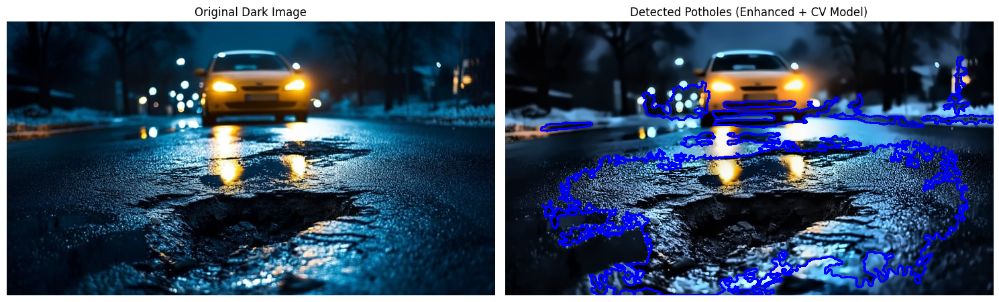

In [30]:
# ===============================================================
# 🌙 Night Vision Enhancement + Pothole Detection (Single Image)
# ===============================================================

# --- Imports ---
import cv2
import os
import joblib
import numpy as np
import matplotlib.pyplot as plt
from skimage.feature import graycomatrix, graycoprops, local_binary_pattern

# --- Paths ---
IMG_PATH = "/kaggle/input/darkimage/StockCake-Nighttime_road_pothole_1762355549.jpg"
MODEL_PATH = "random_forest_model.pkl"
SCALER_PATH = "scaler_supervised.pkl"

# --- Load Model and Scaler ---
model = joblib.load(MODEL_PATH)
scaler = joblib.load(SCALER_PATH)

# ===============================
# 1️⃣ Night-Vision Enhancement Function
# ===============================
def image_enhancement(img, clipLimit=3.0, tileGridSize=(8,8), denoise_h=10):
    """
    Enhances low-light BGR images using:
      - LAB + CLAHE for local contrast
      - Adaptive Gamma Correction
      - Denoising for smoothness
    """
    if img is None:
        return None

    lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)

    clahe = cv2.createCLAHE(clipLimit=clipLimit, tileGridSize=tileGridSize)
    l_clahe = clahe.apply(l)
    lab_clahe = cv2.merge((l_clahe, a, b))
    enhanced = cv2.cvtColor(lab_clahe, cv2.COLOR_LAB2BGR)

    mean_l = float(np.mean(l_clahe))
    target = 120.0
    gamma = np.clip(0.6 + (target - mean_l) / 256.0, 0.4, 1.6)
    invGamma = 1.0 / gamma
    table = np.array([((i / 255.0) ** invGamma) * 255 for i in np.arange(256)]).astype("uint8")
    gamma_corrected = cv2.LUT(enhanced, table)

    denoised = cv2.fastNlMeansDenoisingColored(gamma_corrected, None,
                                               h=denoise_h, hColor=denoise_h,
                                               templateWindowSize=7, searchWindowSize=21)
    return denoised

# ===============================
# 2️⃣ Feature Extraction Function
# ===============================
def extract_features_for_prediction(image_bgr, contours, gray_image):
    LBP_RADIUS = 1
    LBP_POINTS = 8 * LBP_RADIUS
    feature_list, valid_contours = [], []

    for contour in contours:
        area = cv2.contourArea(contour)
        if area < 500 or area > 120000:
            continue

        mask = np.zeros(gray_image.shape, dtype=np.uint8)
        cv2.drawContours(mask, [contour], -1, 255, -1)

        x, y, w, h = cv2.boundingRect(contour)
        roi_gray = gray_image[y:y+h, x:x+w]
        roi_mask = mask[y:y+h, x:x+w]

        if roi_mask.sum() == 0:
            continue

        # Edge density
        roi_canny = cv2.Canny(roi_gray, 50, 150)
        roi_canny_masked = cv2.bitwise_and(roi_canny, roi_canny, mask=roi_mask)
        edge_density = np.sum(roi_canny_masked > 0) / area

        # GLCM features
        glcm = graycomatrix(roi_gray, distances=[1], angles=[0], levels=256, symmetric=True, normed=True)
        glcm[0, 0, :, :] = 0
        contrast = graycoprops(glcm, 'contrast')[0, 0]
        homogeneity = graycoprops(glcm, 'homogeneity')[0, 0]
        energy = graycoprops(glcm, 'energy')[0, 0]

        # LBP histogram
        lbp = local_binary_pattern(roi_gray, LBP_POINTS, LBP_RADIUS, method='uniform')
        lbp_masked = lbp[roi_mask == 255]
        (hist, _) = np.histogram(lbp_masked, bins=np.arange(0, LBP_POINTS + 3),
                                 range=(0, LBP_POINTS + 2))
        hist = hist.astype("float")
        hist /= (hist.sum() + 1e-6)

        final_vector = [area, edge_density, contrast, homogeneity, energy]
        feature_list.append(final_vector)
        valid_contours.append(contour)

    return feature_list, valid_contours

# ===============================
# 3️⃣ Run Pothole Detection on the Dark Image
# ===============================
# --- Load and Enhance ---
img_bgr = cv2.imread(IMG_PATH)
if img_bgr is None:
    raise FileNotFoundError(f"❌ Could not read image at {IMG_PATH}")

enhanced_img = image_enhancement(img_bgr)
gray = cv2.cvtColor(enhanced_img, cv2.COLOR_BGR2GRAY)

# --- Preprocessing for Contour Extraction ---
blur = cv2.medianBlur(gray, 5)
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15))
blackhat = cv2.morphologyEx(blur, cv2.MORPH_BLACKHAT, kernel)
_, thresh = cv2.threshold(blackhat, 10, 255, cv2.THRESH_BINARY)
contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

# --- Feature Extraction ---
features, valid_contours = extract_features_for_prediction(enhanced_img, contours, gray)

# --- Classification & Visualization ---
result_img = enhanced_img.copy()
if features:
    X = scaler.transform(features)
    preds = model.predict(X)
    for contour, label in zip(valid_contours, preds):
        color = (0, 255, 0) if label == 1 else (255, 0, 0)  # Green = pothole, Red = junk
        cv2.drawContours(result_img, [contour], -1, color, 2)

# --- Plot Results ---
plt.figure(figsize=(15, 6))
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB))
plt.title("Original Dark Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(result_img, cv2.COLOR_BGR2RGB))
plt.title("Detected Potholes (Enhanced + CV Model)")
plt.axis("off")

plt.tight_layout()
plt.show()


# Conclusion

In this project, we successfully built a **traditional computer vision–based pothole detection system** using **supervised learning** and **handcrafted features**.

### 🧩 Key Achievements:
- Used an **annotated dataset** with ground-truth bounding boxes for accurate labeling.  
- Designed a full pipeline — from **candidate generation** → **feature extraction** → **classification** → **severity mapping**.  
- Balanced the dataset using **SMOTE** and trained a **Random Forest model** for pothole classification.  
- Measured inference speed of **~0.07 seconds per frame (~13.7 FPS)**, showing **real-time capability**.  
- Visualized strong qualitative results on test images with accurate detections.

### 🚧 Limitations & Future Work:
- More **features** (HOG, LBP, color, shape descriptors) could improve accuracy.  
- Potential extension: integrate with a mobile or drone-based live detection system.

Overall, this project demonstrates a **robust and explainable CV-based solution** for pothole detection without using deep learning, combining **interpretability, and efficiency**.
